In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

print("Libraries imported successfully")

Libraries imported successfully


Create Database

In [59]:
#step 2
data = pd.read_csv('/content/ac_dataset(1).csv')
df = pd.DataFrame(data)
print(df)

          Brand  Quantity  Capacity_Ton  Star_Rating Inverter  \
0        Godrej         2          1.00            3      Yes   
1         Haier         1          2.00            3      Yes   
2     Whirlpool         3          1.50            5      Yes   
3     Panasonic         1          1.50            1       No   
4       Hitachi         3          1.00            5      Yes   
...         ...       ...           ...          ...      ...   
1495    Hitachi         3          1.50            3      Yes   
1496     Voltas         3          1.00            5      Yes   
1497  O General         6          2.00            5      Yes   
1498  Panasonic         2          0.75            4      Yes   
1499         LG         2          2.00            5      Yes   

      Power_Consumption_W  Cooling_Capacity_BTU  Total_Price_INR  
0                     690                 12000            55000  
1                    1315                 24000            45900  
2                 

Inspect the **Dataset**

In [60]:
#step 3
print("First five rows:")
print(df.head())

print("Last five rows:")
print(df.tail())

print("\n Dataset shape :")
print(df.shape)

print("\n Column names:")
print(df.columns)

print("\n Number of Rows:")
print(df.shape[0])

print("\n Number of columns:")
print(df.shape[1])

print("\nDataset Description or summary:")
print(df.describe())

print("\nDataset Information:")
print(df.info())

First five rows:
       Brand  Quantity  Capacity_Ton  Star_Rating Inverter  \
0     Godrej         2           1.0            3      Yes   
1      Haier         1           2.0            3      Yes   
2  Whirlpool         3           1.5            5      Yes   
3  Panasonic         1           1.5            1       No   
4    Hitachi         3           1.0            5      Yes   

   Power_Consumption_W  Cooling_Capacity_BTU  Total_Price_INR  
0                  690                 12000            55000  
1                 1315                 24000            45900  
2                  825                 18000           118800  
3                 1545                 18000            30600  
4                  550                 12000           126600  
Last five rows:
          Brand  Quantity  Capacity_Ton  Star_Rating Inverter  \
1495    Hitachi         3          1.50            3      Yes   
1496     Voltas         3          1.00            5      Yes   
1497  O General

Check Data **quality**

In [61]:
#step 4
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
Brand                   0
Quantity                0
Capacity_Ton            0
Star_Rating             0
Inverter                0
Power_Consumption_W     0
Cooling_Capacity_BTU    0
Total_Price_INR         0
dtype: int64

Duplicate rows:
2


Data **Visualisation**

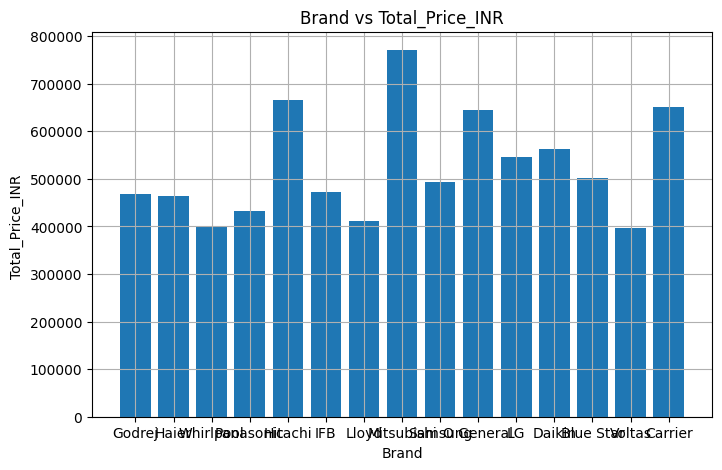

In [62]:
plt.figure(figsize=(8,5))
plt.bar(df["Brand"],df["Total_Price_INR"])
plt.xlabel("Brand")
plt.ylabel("Total_Price_INR ")
plt.title("Brand vs Total_Price_INR")
plt.grid(True)
plt.show()

`Prepring Data for Machine Learning

Separate featurs and target

In [63]:
x = df[["Brand","Quantity"]]
y = df["Total_Price_INR"]

print("features (x):")
print(x)

print("Target (y):")
print(y)

features (x):
          Brand  Quantity
0        Godrej         2
1         Haier         1
2     Whirlpool         3
3     Panasonic         1
4       Hitachi         3
...         ...       ...
1495    Hitachi         3
1496     Voltas         3
1497  O General         6
1498  Panasonic         2
1499         LG         2

[1500 rows x 2 columns]
Target (y):
0        55000
1        45900
2       118800
3        30600
4       126600
         ...  
1495    133200
1496    111900
1497    486000
1498     67000
1499    129600
Name: Total_Price_INR, Length: 1500, dtype: int64


In [64]:
# Train test Split
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42)

print("Training Samples:", len(x_train))

print("Testing Samples:", len(x_test))

Training Samples: 1200
Testing Samples: 300


In [65]:
# Brand ko numerical format mein convert karna
preprocessor = ColumnTransformer(
    transformers=[
        ('brand', OneHotEncoder(handle_unknown='ignore'), ['Brand'])
    ],
    remainder='passthrough'
)

# Pipeline banana
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Model train karna
model.fit(x_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [66]:
#Create the model
model = LinearRegression()

In [67]:
# Re-create and train using the preprocessing pipeline
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(x_train, y_train)
print("Model Training Completed!")

Model Training Completed!


In [68]:
#Inspect learned parameters
y_pred = model.predict(x_test)

print("Predicted Prices:")
print(y_pred[:10])

Predicted Prices:
[ 48634.99912721  65420.67966635  29346.06270778 117921.87620237
 149420.77576156 124441.77770916 111488.05891594  86115.28907792
  26938.70567546  86115.28907792]


In [69]:
#Compare Actual and predicted values
comparison_df = pd.DataFrame({
    "Actual":y_test,
   "Predicted":y_pred
    })
print(comparison_df)

      Actual      Predicted
1116   48300   48634.999127
1368   67200   65420.679666
422    43900   29346.062708
413   106200  117921.876202
451   147000  149420.775762
...      ...            ...
983    32000   26938.705675
799   141600  170671.091453
1265   57600   64626.348630
1150  441900  413844.612544
824    44900   64871.422521

[300 rows x 2 columns]


In [70]:
#Mean Absolute error
mae = mean_absolute_error(y_test,y_pred)
print("Mean Absolute Error:",mae)

Mean Absolute Error: 23911.971110549188


In [71]:
mse = mean_squared_error(y_test,y_pred)
print("Mean Squared Error:",mse)

Mean Squared Error: 1203306746.5883641


In [72]:
rmse = np.sqrt(mse)
print("Root Mean Squared Error:",rmse)

Root Mean Squared Error: 34688.71209180825


In [73]:
r2=r2_score(y_test,y_pred)
print("R2 Score:",r2)


R2 Score: 0.8894507920464888


In [74]:
# Predict price for a new AC order

new_ac = pd.DataFrame({
    "Brand": ["LG"],
    "Quantity": [6]
})

predicted_price = model.predict(new_ac)

print("Brand:", new_ac["Brand"].values[0])
print("Quantity:", new_ac["Quantity"].values[0])
print("Predicted Total Price:", round(predicted_price[0], 2))

Brand: LG
Quantity: 6
Predicted Total Price: 255214.0


In [75]:
import joblib

# Save the trained model
joblib.dump(model, "Ac_price_model.ipynb")

print("Model saved successfully!")

Model saved successfully!


In [76]:
from google.colab import files

# Download the trained model
files.download("Ac_price_model.ipynb")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>